**Supplied reference run.** All seven code cells were executed with IPython in a single Linux Python process. This reference captures real model results. This build host does not allow Jupyter kernel socket binding, so the live browser/kernel/SSH path must still be preflighted on the teaching server. Run the clean notebook in the parent folder for your own experiment; this copy is for viewing.

# Build a cloud, change the radiation
### A 50-minute RTE+RRTMGP experiment

**Question:** How does the amount and vertical placement of liquid water and ice change the radiation reaching the surface and escaping toward space?

Run this notebook on the **Linux server**, viewing it from your Windows or Mac laptop. Complete `GETTING_STARTED.md` before class. Use **Shift+Enter** to run each cell in order. The first installation is prework; this notebook can also start that installation from an existing Linux Jupyter session.

By the end, you will have run the actual radiation engine, built a mass-conserving cloud, tested a prediction, and saved figures plus a result record to your GitHub fork.

| Minutes | Your task |
|---|---|
| 0–5 | Predict a cloud's effect on sunlight at the surface |
| 5–10 | Check the engine and learn the flux vocabulary |
| 10–20 | Run and interpret the baseline |
| 20–30 | Build your own cloud and check its mass |
| 30–42 | Run your experiment and compare |
| 42–47 | Explain one change and one assumption |
| 47–50 | Save a result to your GitHub fork |

**Before running:** write a prediction below. Does adding liquid water increase or decrease the sunlight reaching the surface? Why?

**My prediction:** _Double-click this Markdown cell and write one sentence._

## 1. Download/check the model — 5–10 minutes

The installer retrieves the pinned official source repositories and coefficient tables, and creates an isolated Python environment with a precompiled Fortran library. It reuses completed downloads on subsequent runs. It needs network access on the first run; it does not need administrator rights.

This workshop preserves the prior ROMANS stack: **Python interface 0.2.5 + executing Fortran library 1.9.2**. It also downloads the **1.9.3 source checkout for inspection**. Downloading that source does not mean the Python kernel executes 1.9.3. Package versions and data hashes are recorded for reproducibility.

If this cell installs into a different Python environment, follow the printed kernel instruction and then rerun from the top. The rest of the lesson assumes installation has already finished.

In [1]:
from pathlib import Path
import os
import platform
import subprocess
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "setup_workshop.sh").is_file():
    raise RuntimeError("Open the notebook from the extracted workshop folder, alongside setup_workshop.sh.")
if platform.system() != "Linux" or platform.machine() not in ("x86_64", "AMD64"):
    raise RuntimeError("Run this notebook's kernel on an x86_64 Linux server. Windows/macOS are browser and SSH clients.")
# Keep 20–30 independent participants from each starting many numerical threads.
for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[name] = "1"
os.environ["PYTHONNOUSERSITE"] = "1"
subprocess.run(["bash", str(ROOT / "setup_workshop.sh")], cwd=ROOT, check=True)
expected = (ROOT / "envs" / "rrtmgp").resolve()
print("Current Python:", sys.executable)
if Path(sys.prefix).resolve() != expected:
    raise RuntimeError("Setup finished. Select Kernel → Change Kernel → Python (RRTMGP Workshop), then restart and run from the top. If absent, restart Jupyter from envs/rrtmgp/bin/jupyter lab.")
print("Workshop environment is ready.")

Current Python: /workspace/scratch/c079ffa8fb94/RRTMGP_Cloud_Workshop_v1.0/envs/rrtmgp/bin/python
Workshop environment is ready.


In [2]:
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, FileLink
from workshop_model import (build_column, run_column, save_case,
                            plot_profiles, boundary_summary, verify_reference,
                            find_data_dir)

OUTPUT = ROOT / "outputs"
OUTPUT.mkdir(exist_ok=True)
print("Coefficient directory:", find_data_dir())
# First import/table load can take longer than subsequent experiments.
start = time.perf_counter()
reference_errors = verify_reference()
display(pd.DataFrame({"Flux": reference_errors.keys(),
                      "Maximum absolute reference difference (W/m²)": reference_errors.values()}))
print(f"Official clear/cloudy reference columns passed in {time.perf_counter()-start:.1f} s.")

Coefficient directory: /workspace/scratch/c079ffa8fb94/RRTMGP_Cloud_Workshop_v1.0/.cache/rrtmgp-data
Official clear/cloudy reference columns passed in 0.5 s.


,Flux,Maximum absolute reference difference (W/m²)
0,sw_flux_up,0.000003
1,sw_flux_down,0.000003
2,lw_flux_up,0.000006
3,lw_flux_down,0.000006


**What did the check test?** It reproduced the upstream 24-column all-sky example, which includes both cloud-free and cloudy columns, and compared its SW/LW upward and downward fluxes with supplied reference files. It fails visibly if the answers disagree beyond `rtol=1e-5, atol=1e-7 W m⁻²`. This checks implementation; it is **not** an uncertainty estimate for your invented cloud.

**Two jobs, one calculation.** RRTMGP converts pressure, temperature, and gas concentrations into gas optical properties and emission sources. RTE combines these with the boundary conditions to calculate fluxes. We supply cloud optical properties separately. This separation lets us change the cloud while holding the atmosphere fixed. *(Pincus et al., 2019, sections 2.2–2.4, pp. 3077–3079; paraphrased.)*

**Why lookup tables?** Gases absorb very differently across the spectrum. The correlated-k method groups absorption of similar strength within bands and represents a spectral integral using weighted samples called **g-points**. A g-point is not a single fixed wavelength. The coefficient tables affect both accuracy and cost; they belong in the reproducibility record. We use the pinned 224-point SW and 256-point LW tables. *(Pincus et al., sections 2.3 and 3.1; counts verified for the selected files.)*

## 2. Baseline: follow the energy — 10–20 minutes

**Shortwave (SW)** is sunlight. **Longwave (LW)** is thermal infrared radiation from the surface, atmosphere, and cloud. Flux measures power per unit area, in W m⁻².

We run the same atmospheric column twice: **clear sky** removes cloud water and ice; **all sky** includes them. Temperatures, gases, sunlight, and surface properties stay fixed. Here “all sky” means one horizontally uniform, fully cloudy column wherever cloud water is present, not a partly cloudy area average.

The teaching atmosphere extends from the surface to 60 km. Its surface temperature is 278 K, surface pressure 101325 Pa, solar zenith angle 60°, albedo 0.15, and emissivity 0.98. Temperature and gases are prescribed analytic profiles, not CAESAR observations. The baseline cloud extends from 1.5 to 2.5 km, with LWP 100 and IWP 30 g m⁻². Liquid effective radius is 10 µm and ice effective **diameter** is 60 µm. Those particle sizes and the fixed ice roughness are teaching choices.

Radiation does not exchange energy with neighboring columns. SW uses a two-stream solver with delta scaling of cloud optics; the selected LW solver uses absorption and emission with one quadrature angle and neglects LW scattering. RTE also supports other solver choices. *(Framework: Pincus et al., introduction and section 2.2; this particular configuration is our choice.)*

Baseline pair finished in 1.4 s (including saving figures).


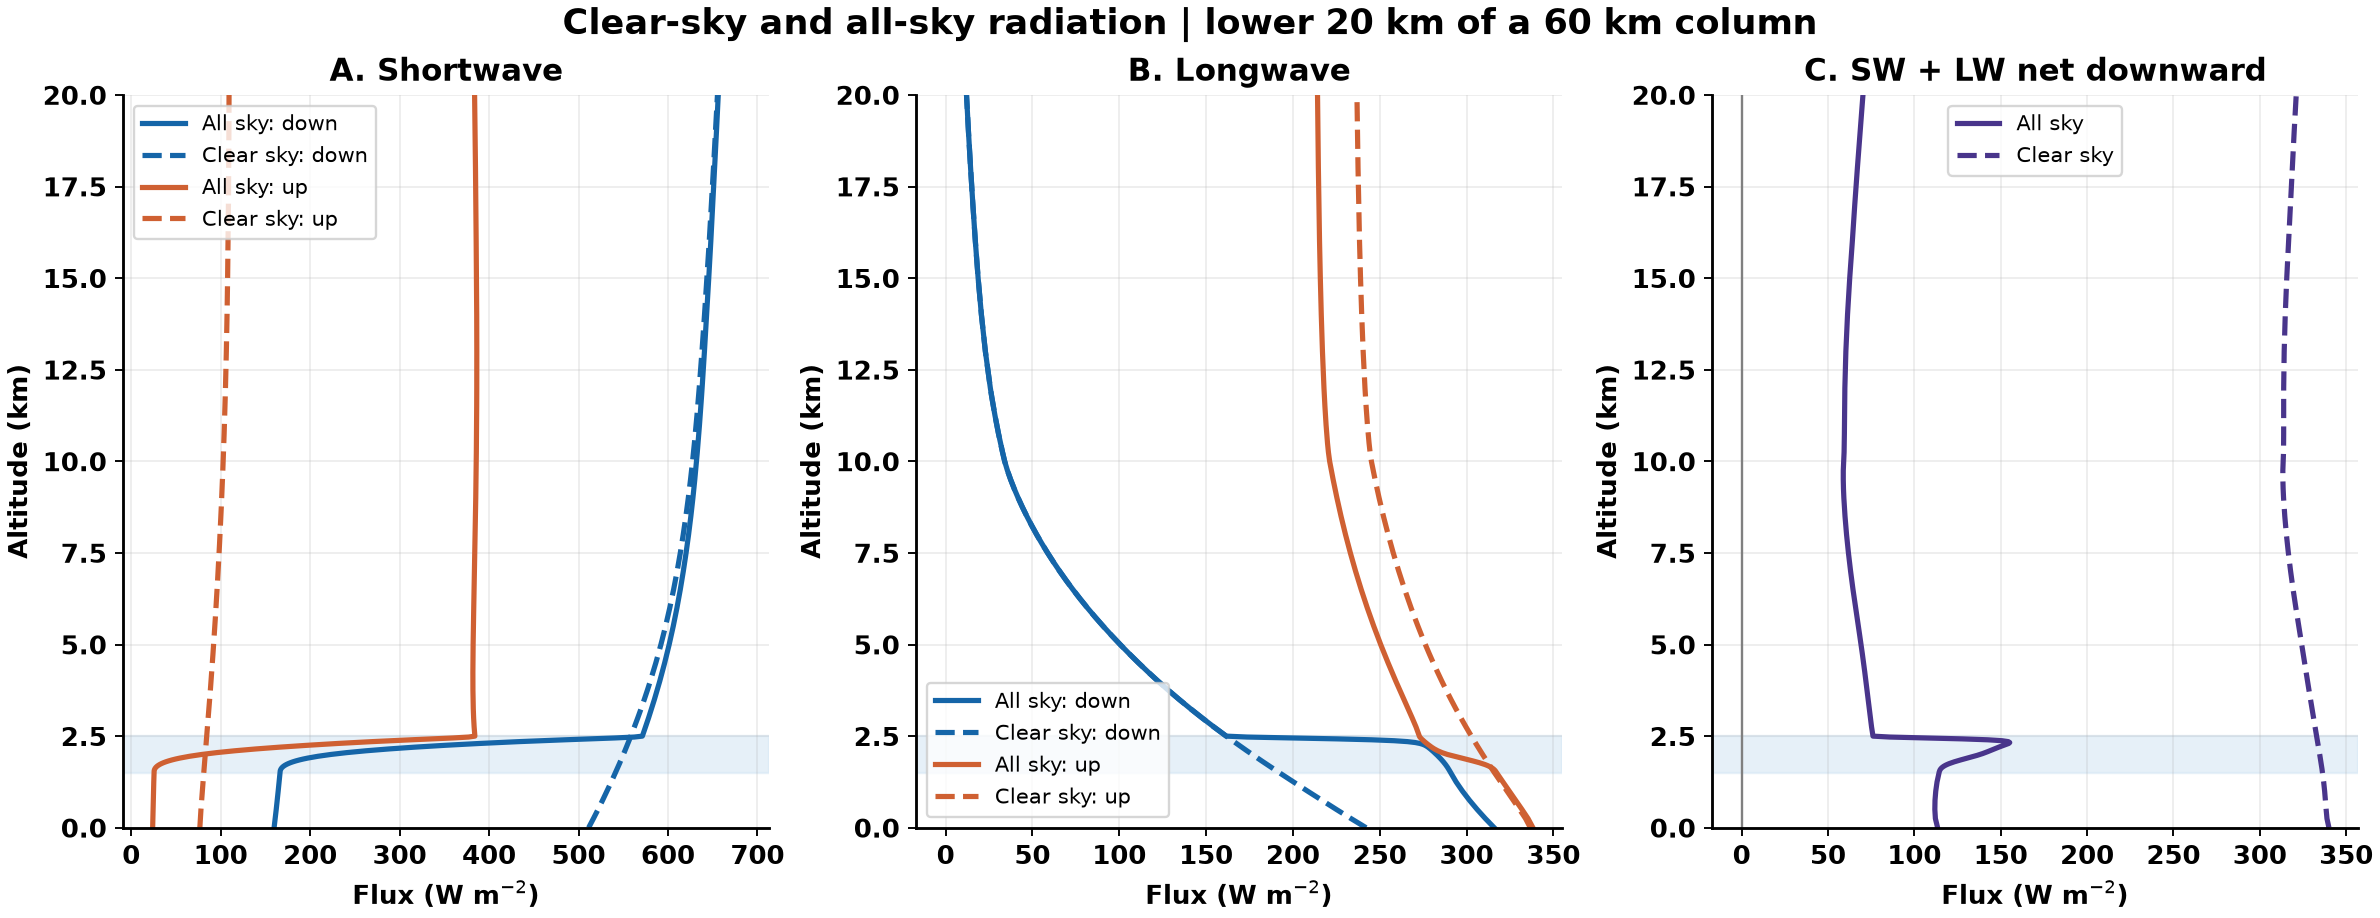

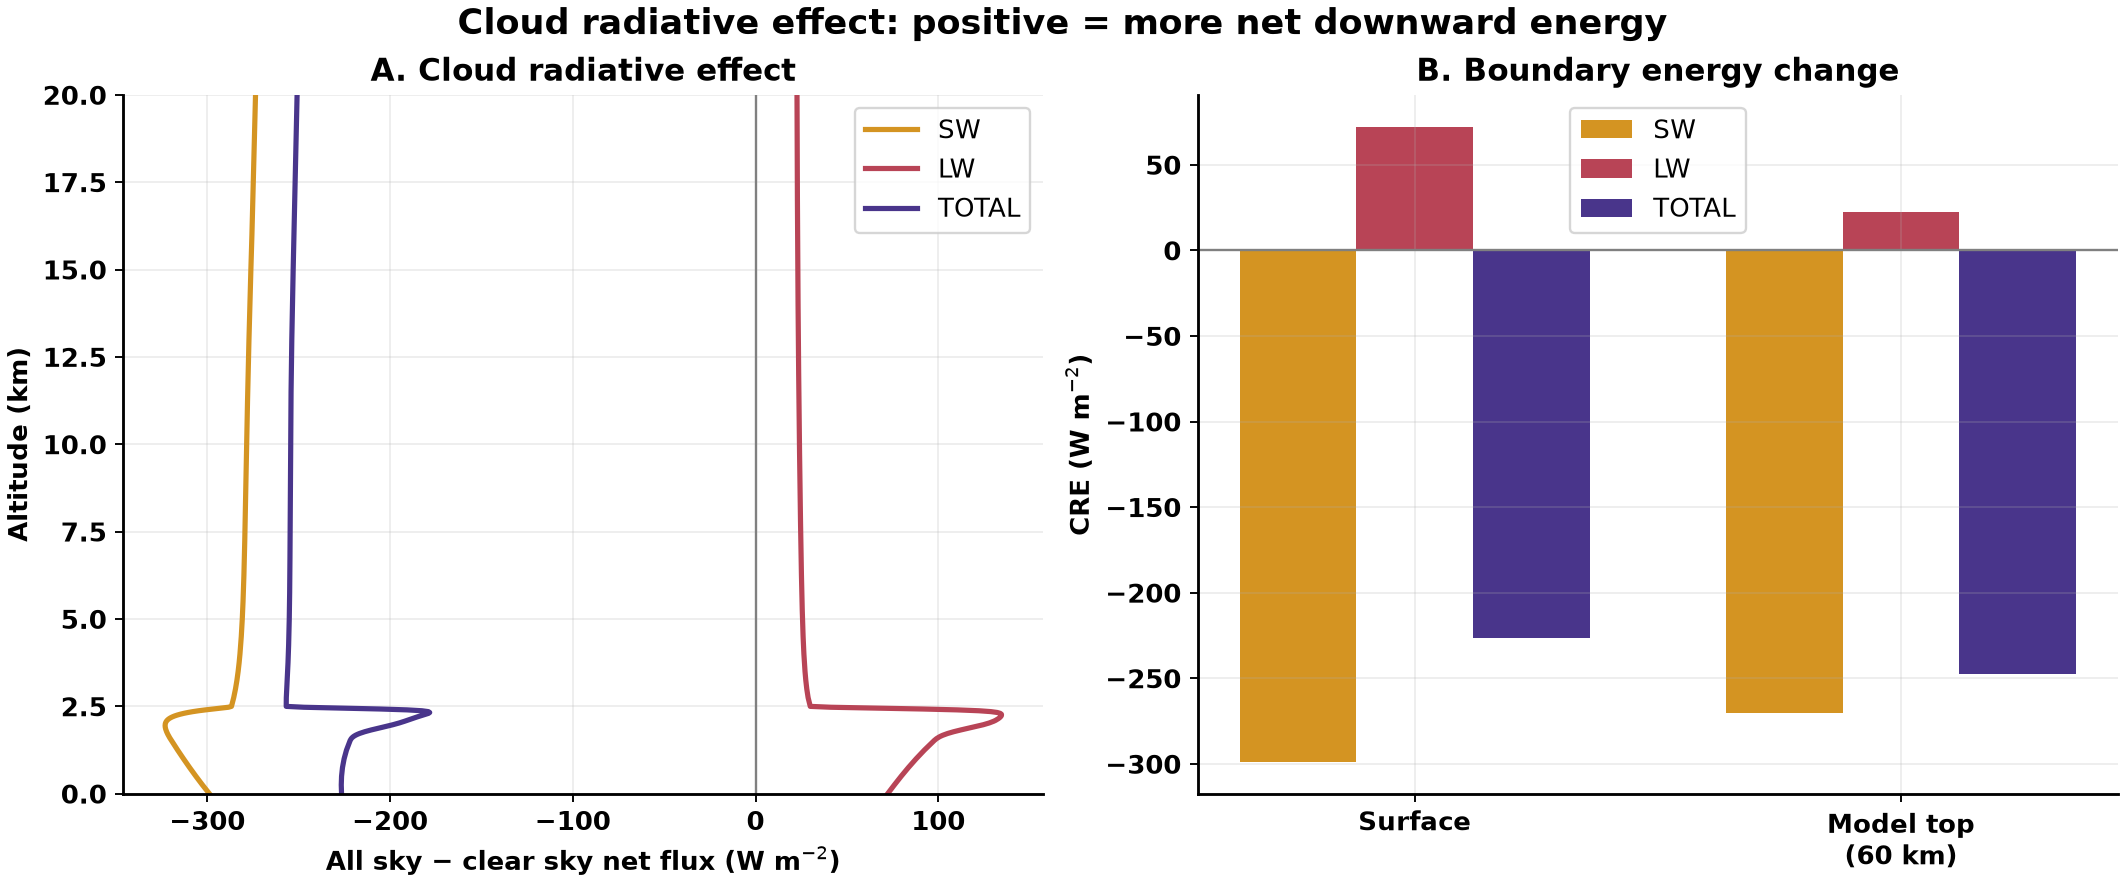

,Boundary,Band,Clear net (W/m²),All-sky net (W/m²),CRE (W/m²)
0,Surface,SW,434.57,135.73,-298.84
1,Surface,LW,-94.57,-22.27,72.30
2,Surface,TOTAL,340.00,113.46,-226.54
3,Model top (60 km),SW,570.12,299.96,-270.15
4,Model top (60 km),LW,-238.56,-216.12,22.44
5,Model top (60 km),TOTAL,331.56,83.84,-247.71


In [3]:
baseline_parameters = dict(depth_m=1000.0, lwp_gm2=100.0, iwp_gm2=30.0)
baseline_atmosphere = build_column(**baseline_parameters)
start = time.perf_counter()
baseline = run_column(baseline_atmosphere)
baseline_files = save_case(baseline, OUTPUT, "baseline")
print(f"Baseline pair finished in {time.perf_counter()-start:.1f} s (including saving figures).")
display(Image(filename=str(baseline_files["fluxes"])))
display(Image(filename=str(baseline_files["cre"])))
display(boundary_summary(baseline).round(2))

**Read the plots.** Solid lines are all sky; dashed lines are clear sky. Upward and downward fluxes are positive magnitudes in their own directions. The flux quicklook shows the lower 20 km; the table includes the model top at 60 km, used here as an approximate top-of-atmosphere boundary.

We use a net-downward sign convention:

$$F_\mathrm{net}=F_\downarrow-F_\uparrow,\qquad
\mathrm{CRE}=F_{\mathrm{net,all}}-F_{\mathrm{net,clear}}.$$

Positive **cloud radiative effect (CRE)** at the surface means more radiative energy entering the surface. Positive CRE at the top means more energy entering the combined atmosphere–surface system. Neither boundary value alone is the atmospheric heating rate.

**Discuss:** Which direction of SW changes most near the surface? Why can a cloud reduce surface sunlight but increase downward LW? Do those effects cancel in this case?

## 3. Design a cloud — 20–30 minutes

A **water path** is mass per unit horizontal area; a **water content** is mass per unit volume:

$$\mathrm{LWP}=\int \mathrm{LWC}(z)\,dz,\qquad
\mathrm{IWP}=\int \mathrm{IWC}(z)\,dz.$$

Enter paths in **g m⁻²** and cloud depth in **m**. The plots show content in **g m⁻³**. Water paths alone do not determine radiation: particle sizes and ice optical assumptions also matter. We hold those fixed in the main experiment. Pincus et al. emphasize the user's responsibility for the cloud-to-optics mapping *(section 4, pp. 3086–3087)*.

For normalized cloud altitude $x=(z-z_b)/H$, with base $z_b$ and depth $H$, we prescribe:

$$\mathrm{LWC}(z)=\frac{\mathrm{LWP}}{H}\,30x^4(1-x),\qquad
\mathrm{IWC}(z)=\frac{\mathrm{IWP}}{H}\,60x^2(1-x)^3,\quad 0\le x\le1.$$

Both shapes integrate to one before multiplying by path/depth. Their smooth peaks occur at **x = 0.8 for liquid** and **x = 0.4 for ice**. These skewed beta curves give the requested curved rise and fall; a pure exponential cannot peak inside the cloud. **The shapes are workshop assumptions, not a parameterization from the paper.**

The code integrates each curve across layer boundaries using its beta cumulative distribution. Each layer receives an exact fraction of the path, including for 50 m clouds, which have at least 40 layers. Layer-average maxima can differ slightly from the continuous peak locations.

**Change only one variable first.** The supplied experiment doubles LWP relative to the baseline. Choose another group assignment from the instructor if requested.

,Phase,Requested path (g/m²),Integrated path (g/m²)
0,Liquid,200.0,200.0
1,Ice,30.0,30.0


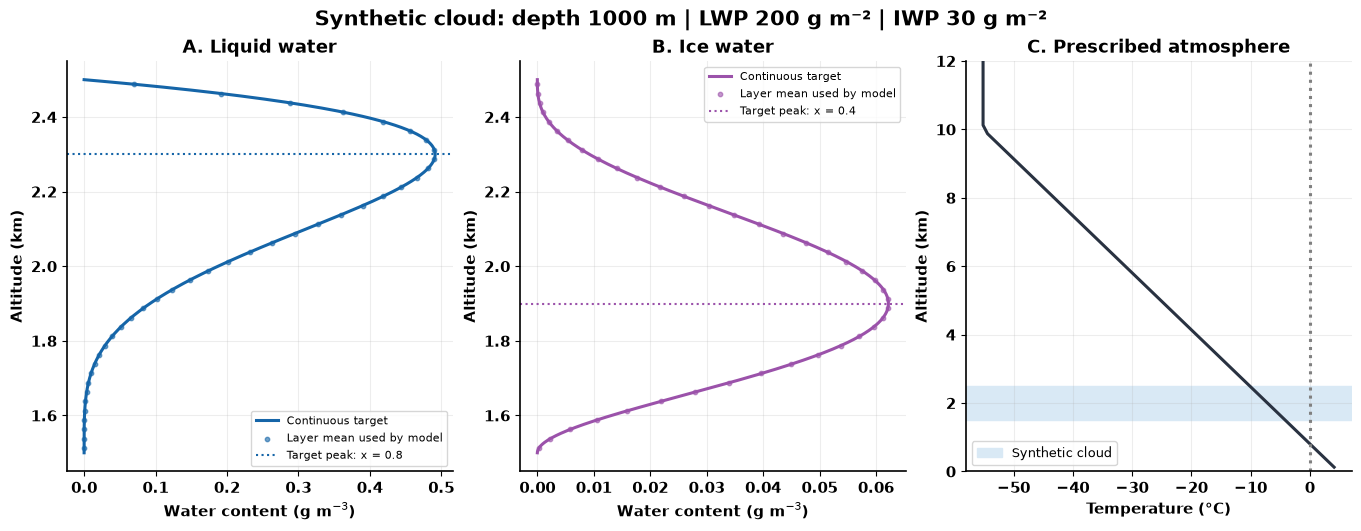

In [4]:
# -------- EDIT THESE THREE CLOUD PARAMETERS --------
CLOUD_DEPTH_M = 1000.0   # Allowed range: 50–3000 m.
LWP_G_M2 = 200.0         # Nonnegative; baseline is 100 g/m².
IWP_G_M2 = 30.0          # Nonnegative; baseline is 30 g/m².

# Use a new simple name before rerunning to preserve earlier experiment files.
EXPERIMENT_NAME = "experiment01"
PREDICTION = ""          # Optional: write your prediction before calculating.

experiment_atmosphere = build_column(
    depth_m=CLOUD_DEPTH_M, lwp_gm2=LWP_G_M2, iwp_gm2=IWP_G_M2)

# Layer means require a finite-volume sum, not a trapezoid rule at layer centers.
recovered_lwp = float((experiment_atmosphere.lwc * experiment_atmosphere.layer_thickness).sum())
recovered_iwp = float((experiment_atmosphere.iwc * experiment_atmosphere.layer_thickness).sum())
np.testing.assert_allclose([recovered_lwp, recovered_iwp], [LWP_G_M2, IWP_G_M2], atol=1e-10)
display(pd.DataFrame({"Phase": ["Liquid", "Ice"],
                      "Requested path (g/m²)": [LWP_G_M2, IWP_G_M2],
                      "Integrated path (g/m²)": [recovered_lwp, recovered_iwp]}))
fig = plot_profiles(experiment_atmosphere)
plt.show()
plt.close(fig)

**Checkpoint:** Locate both peaks. If you double depth while holding paths fixed, what happens to average water content? The two contents are not required to peak at the same altitude.

Cloud water is imposed on a fixed atmosphere. This is an optical experiment: no condensation, freezing, precipitation, latent heating, or adjustment to temperature/humidity is simulated. Some extreme combinations can be physically unrealistic even when the radiative calculation is valid.

## 4. Test your prediction — 30–42 minutes

Run the pair with your new cloud. The clear run is recomputed on the same grid as its cloudy partner. Depth changes also change the grid, so compare paired CRE rather than assuming every clear flux is identical across depth experiments.

Experiment pair finished in 1.2 s (including saving figures).


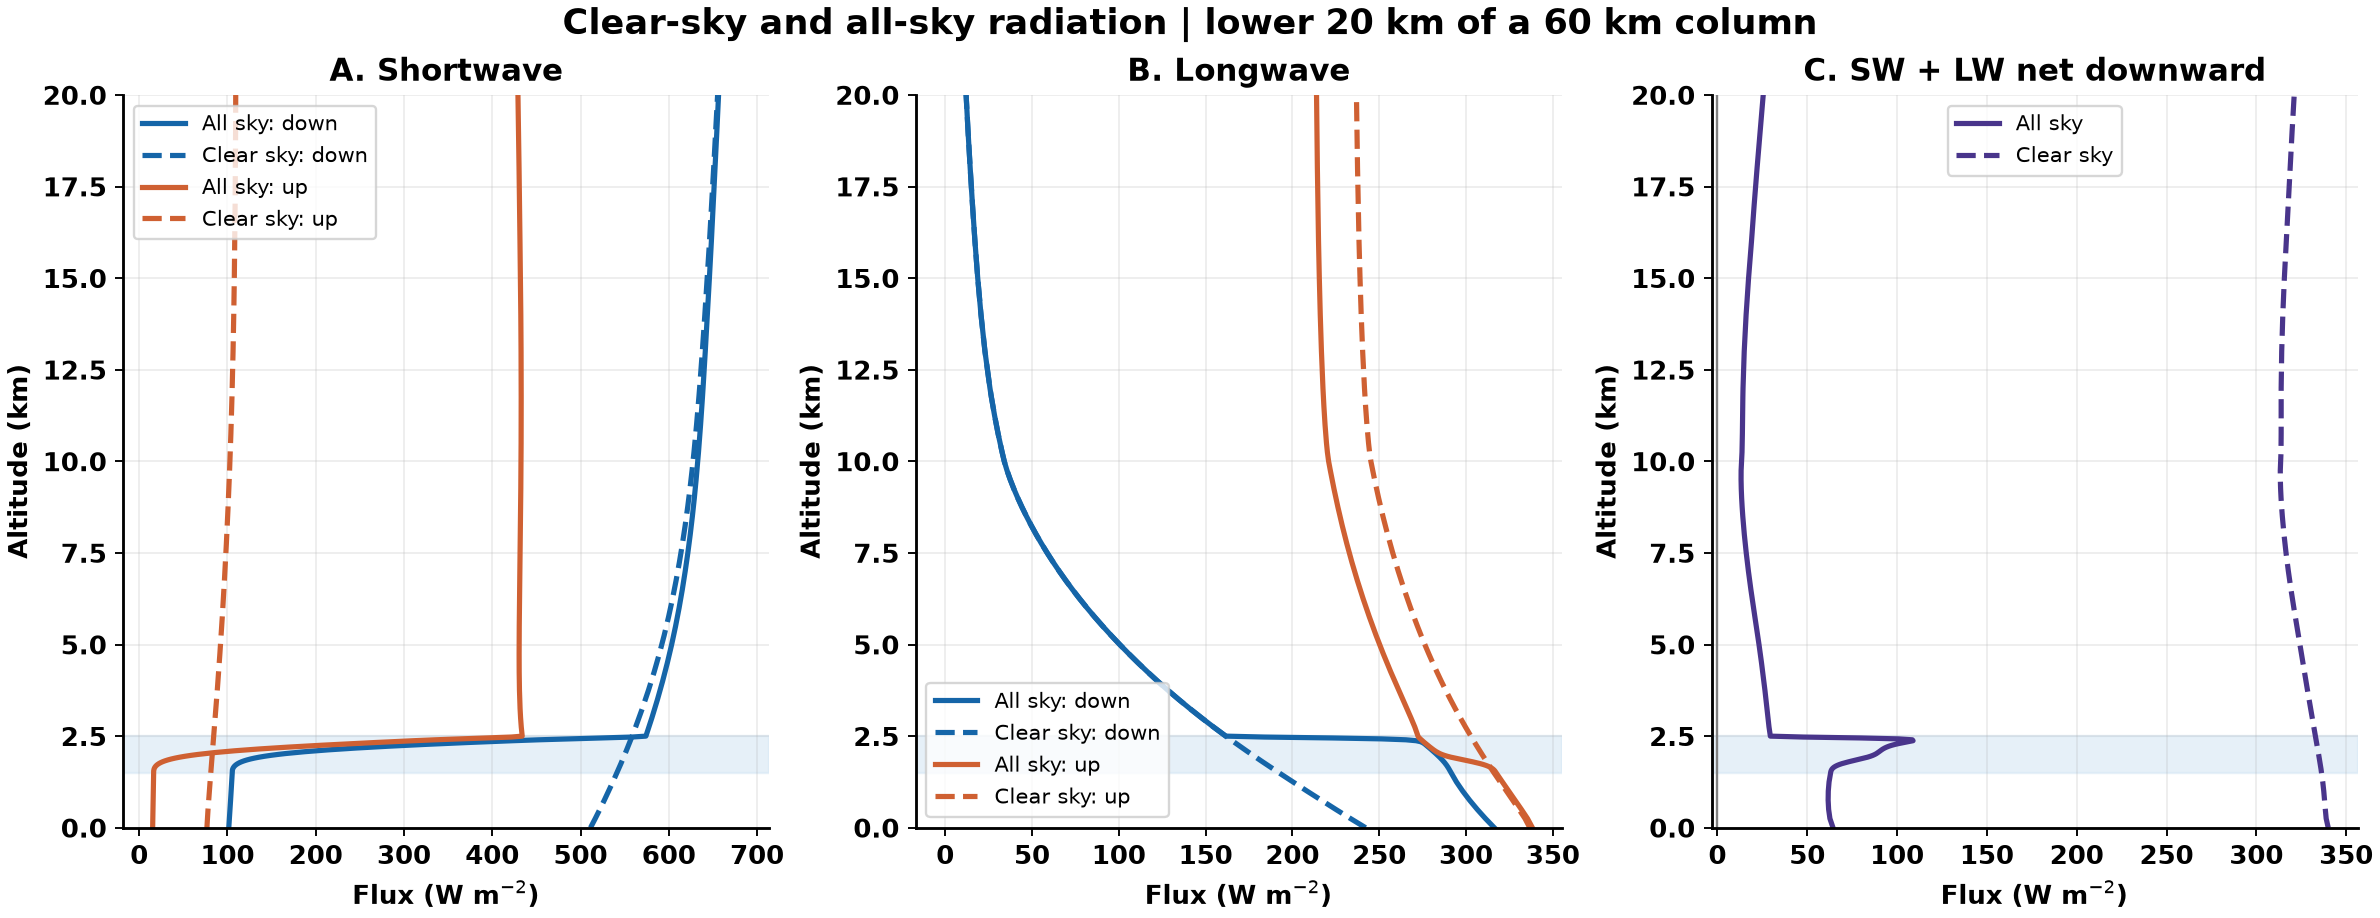

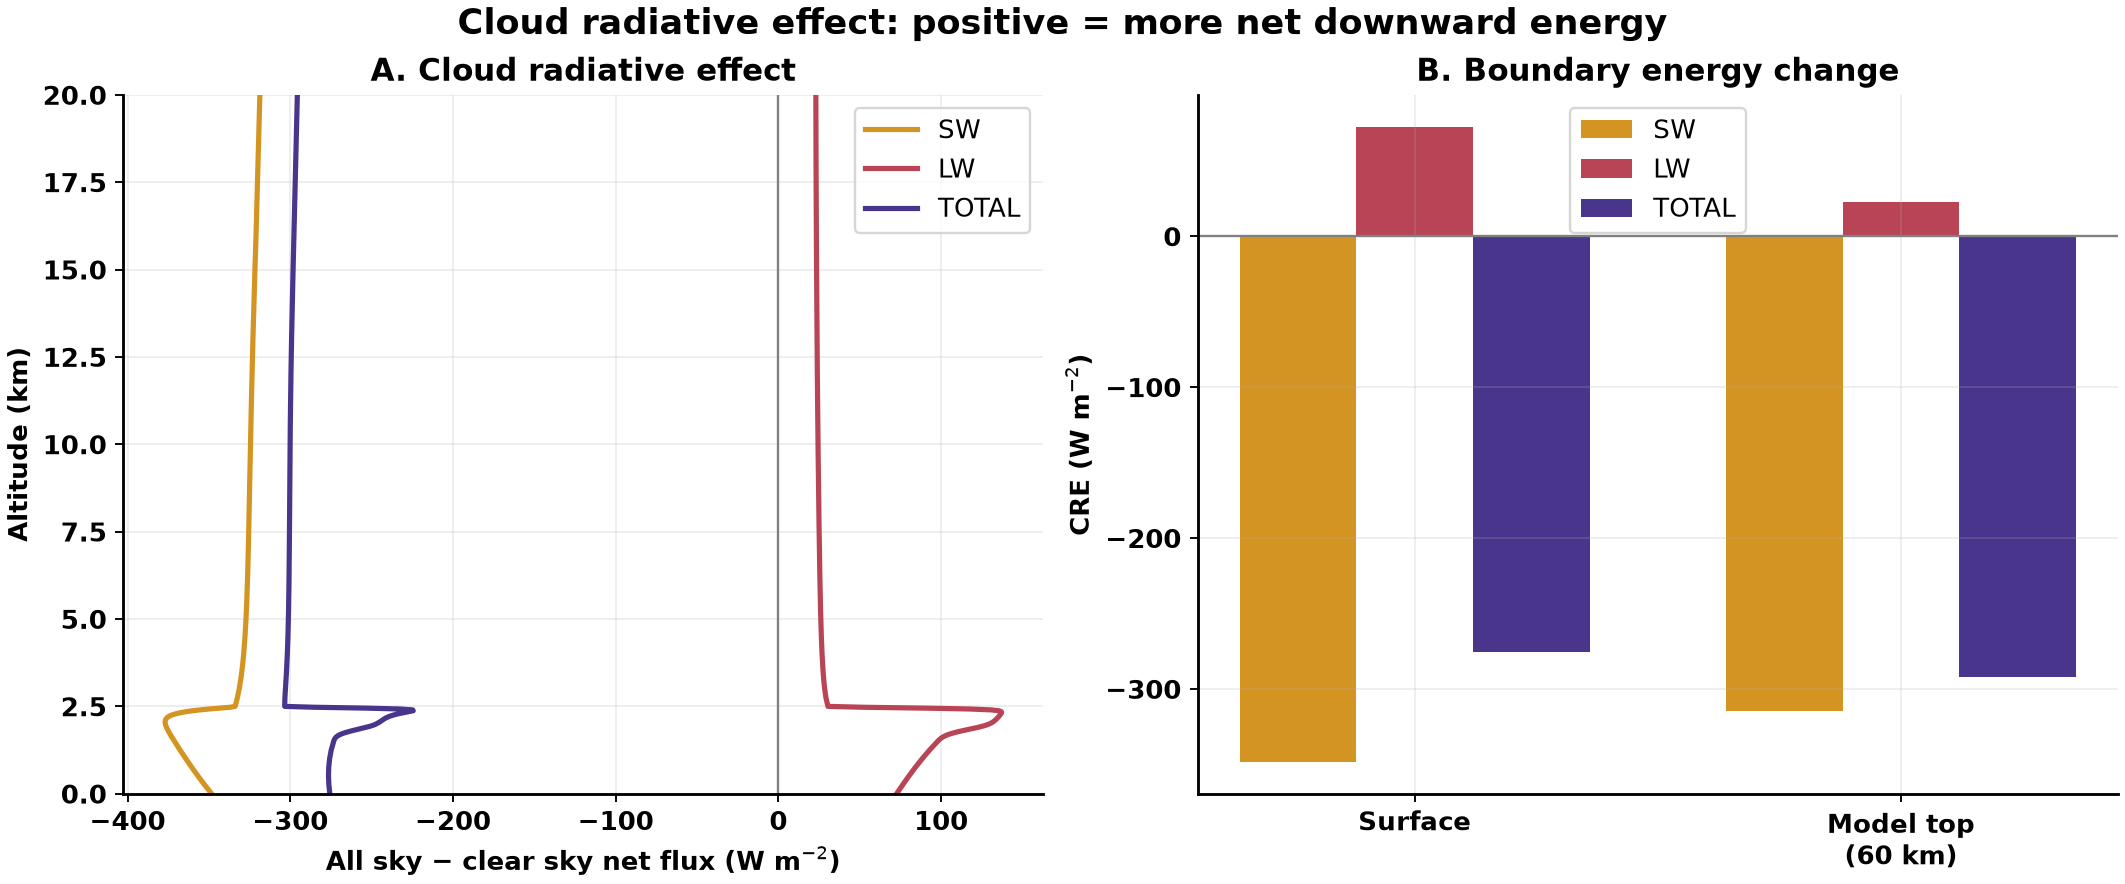

,Boundary,Band,Baseline CRE (W/m²),Experiment CRE (W/m²),Change in CRE (W/m²)
0,Surface,SW,-298.84,-348.32,-49.48
1,Surface,LW,72.30,72.64,0.34
2,Surface,TOTAL,-226.54,-275.68,-49.14
3,Model top (60 km),SW,-270.15,-314.56,-44.41
4,Model top (60 km),LW,22.44,22.73,0.29
5,Model top (60 km),TOTAL,-247.71,-291.84,-44.12


In [5]:
start = time.perf_counter()
experiment = run_column(experiment_atmosphere)
experiment_files = save_case(experiment, OUTPUT, EXPERIMENT_NAME)
print(f"Experiment pair finished in {time.perf_counter()-start:.1f} s (including saving figures).")
display(Image(filename=str(experiment_files["fluxes"])))
display(Image(filename=str(experiment_files["cre"])))

base_table = boundary_summary(baseline)
new_table = boundary_summary(experiment)
comparison = base_table[["Boundary", "Band", "CRE (W/m²)"]].rename(
    columns={"CRE (W/m²)": "Baseline CRE (W/m²)"}).merge(
    new_table[["Boundary", "Band", "CRE (W/m²)"]].rename(
        columns={"CRE (W/m²)": "Experiment CRE (W/m²)"}), on=["Boundary", "Band"])
comparison["Change in CRE (W/m²)"] = comparison["Experiment CRE (W/m²)"] - comparison["Baseline CRE (W/m²)"]
display(comparison.round(2))

**Choose one follow-up, if time allows:** double IWP; remove liquid; double depth at fixed paths; or remove both phases. Return to the parameter cell, change the experiment name, then rerun through this section. Keep the other controls fixed.

At fixed water paths and sizes, spreading cloud mass over a greater depth can leave total cloud optical depth similar while changing its vertical temperature placement and distribution relative to absorbing gases. Predict whether SW or LW will respond more strongly; the outcome is not guaranteed to be the same in every atmosphere.

In [6]:
# A physical consistency check: no cloud must reproduce clear sky.
# This is a new, genuine model calculation, not a stored answer.
empty = run_column(build_column(depth_m=CLOUD_DEPTH_M, lwp_gm2=0.0, iwp_gm2=0.0))
for band in ("sw", "lw", "total"):
    np.testing.assert_allclose(empty[f"{band}_flux_net"], empty[f"{band}_flux_net_clear"],
                               rtol=1e-10, atol=1e-8)
print("PASS: zero liquid + zero ice gives matching clear/all-sky net fluxes.")

PASS: zero liquid + zero ice gives matching clear/all-sky net fluxes.


## 5. Explain and share — 42–50 minutes

Discuss with a partner, then complete these statements:

1. I changed ___ while holding ___ fixed.
2. The surface SW/LW/net CRE changed by ___ W m⁻² because ___.
3. One assumption that limits applying this result to a real cloud is ___.

Write your interpretation in the cell below. Save the notebook, then download the result CSV and one PNG from Jupyter. In **your own GitHub fork**, use **Add file → Upload files** and commit them with a short descriptive message. Your GitHub account stores the results; model downloads do not require a GitHub login.

In [7]:
INTERPRETATION = ""   # Add two or three sentences before sharing.

record = comparison.copy()
record["experiment_name"] = EXPERIMENT_NAME
record["baseline_depth_m"] = baseline_parameters["depth_m"]
record["baseline_lwp_g_m2"] = baseline_parameters["lwp_gm2"]
record["baseline_iwp_g_m2"] = baseline_parameters["iwp_gm2"]
record["experiment_depth_m"] = CLOUD_DEPTH_M
record["experiment_lwp_g_m2"] = LWP_G_M2
record["experiment_iwp_g_m2"] = IWP_G_M2
record["prediction"] = PREDICTION
record["interpretation"] = INTERPRETATION
record.to_csv(OUTPUT / "experiment_record.csv", index=False)
record.to_csv(OUTPUT / f"{EXPERIMENT_NAME}_record.csv", index=False)
print("Saved numerical results. Add your interpretation before uploading if still blank.")
display(FileLink("outputs/experiment_record.csv"))
display(FileLink(str(experiment_files["fluxes"].relative_to(ROOT))))
display(FileLink(str(experiment_files["profiles"].relative_to(ROOT))))
display(FileLink(str(experiment_files["netcdf"].relative_to(ROOT))))

Saved numerical results. Add your interpretation before uploading if still blank.


/workspace/scratch/c079ffa8fb94/RRTMGP_Cloud_Workshop_v1.0/outputs/experiment_record.csv

/workspace/scratch/c079ffa8fb94/RRTMGP_Cloud_Workshop_v1.0/outputs/experiment01_fluxes.png

/workspace/scratch/c079ffa8fb94/RRTMGP_Cloud_Workshop_v1.0/outputs/experiment01_profiles.png

/workspace/scratch/c079ffa8fb94/RRTMGP_Cloud_Workshop_v1.0/outputs/experiment01_radiation.nc

## Optional: look under the hood after class

The readable implementation is in `workshop_model.py`. Its key calls are:

```python
atmosphere = build_column(depth_m=1000, lwp_gm2=100, iwp_gm2=30)
result = run_column(atmosphere)
files = save_case(result, "outputs", "my_case")
```

Within `run_column`, gas optics are recomputed for clear and cloudy runs, cloud optical properties are added for the cloudy run, and the resulting optical problem is passed to RTE. The cloud lookup table requires **layer water paths**, not the total path repeated in every layer. In the pinned wrapper, the variable named `rei` interpolates the **ice effective-diameter** table; the helper passes 60 µm unchanged, not 30 µm. Ice roughness category index 1 (the second tabulated category) is fixed by this wrapper.

NetCDF files retain the atmosphere, input parameters, native fluxes, clear counterparts, net fluxes, CRE, coefficient hashes, and diagnostic heating rates. For net-downward flux and pressure decreasing upward, the diagnostic is

$$Q=-\frac{g}{c_p}\frac{\partial F_\mathrm{net}}{\partial p}\times86400\quad[\mathrm{K\ day^{-1}}].$$

This diagnoses instantaneous radiative heating/cooling; it does not advance the atmospheric temperature.

### References and attribution

Pincus, R., Mlawer, E. J., and Delamere, J. S.: Balancing accuracy, efficiency, and flexibility in radiation calculations for dynamical models, *J. Adv. Model. Earth Syst.*, **11**, 3074–3089, https://doi.org/10.1029/2019MS001621, 2019.

- [RTE+RRTMGP core](https://github.com/earth-system-radiation/rte-rrtmgp)
- [Official Python interface, v0.2.5](https://github.com/earth-system-radiation/pyRTE-RRTMGP/tree/v0.2.5)
- [Coefficient data, v1.9](https://github.com/earth-system-radiation/rrtmgp-data/tree/v1.9)

Teaching text paraphrases the supplied paper. Synthetic cloud profiles, prescribed atmospheric state, particle sizes, and classroom prompts are workshop choices. This is a radiation sensitivity activity, not a validation of a CAESAR retrieval or a synthetic satellite footprint.